# Chapter 7: Ensemble Learning and Random Forests

## 1. Hard Voting Classifier

A **Voting Classifier** trains diverse models on the same dataset and aggregates their individual predictions.
In **hard voting**, the ensemble predicts the class that receives the majority of votes across all individual models.

In [1]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Moons dataset for binary classification
X, y = make_moons(n_samples=500, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

### Training Diverse Classifiers & Hard Voting
We instantiate three different model architectures:
- **Logistic Regression**
- **Random Forest Classifier**
- **Support Vector Classifier (SVC)**

Then combine them into a `VotingClassifier` with `voting='hard'` and evaluate test accuracy for each model.

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

log_clf = LogisticRegression(random_state=42)
rnd_clf = RandomForestClassifier(random_state=42)
svm_clf = SVC(random_state=42)

voting_clf = VotingClassifier(
    estimators=[('lr', log_clf), ('rf', rnd_clf), ('svc', svm_clf)],
    voting='hard'
)

for clf in (log_clf, rnd_clf, svm_clf, voting_clf):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    print(clf.__class__.__name__, accuracy_score(y_test, y_pred))

LogisticRegression 0.864
RandomForestClassifier 0.896
SVC 0.896
VotingClassifier 0.912


### Output Explanation

| Classifier | Accuracy |
| :--- | :--- |
| Logistic Regression | 86.4% |
| Random Forest | 89.6% |
| Support Vector Classifier (SVC) | 89.6% |
| **Voting Classifier (Ensemble)** | **91.2%** |

> **Key Takeaway:** The `VotingClassifier` achieves higher accuracy (**91.2%**) than any of the individual models (**86.4% – 89.6%**).
>
> Even though each classifier makes mistakes on individual instances, they are based on fundamentally different algorithms (linear boundaries, tree partitions, maximum margin hyperplanes). Because their errors are largely independent, their mistakes cancel out when aggregated by majority vote.

## 2. Bagging and Pasting in Scikit-Learn

Instead of training different algorithms on the full dataset, we train **the same algorithm** across **random subsets** of the data.

- `bootstrap=True`: Specifies **Bagging** (sampling with replacement). Set to `False` for **Pasting**.
- `n_estimators=500`: An ensemble of 500 Decision Tree classifiers.
- `max_samples=100`: Each tree is trained on 100 randomly sampled instances.
- `n_jobs=-1`: Tells Scikit-Learn to use all available CPU cores for training and predicting in parallel.

In [3]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

bag_clf = BaggingClassifier(
    DecisionTreeClassifier(random_state=42), n_estimators=500,
    max_samples=100, bootstrap=True, n_jobs=-1, random_state=42
)
bag_clf.fit(X_train, y_train)
y_pred = bag_clf.predict(X_test)

# Compare with a single Decision Tree trained on the same data
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)
y_pred_tree = tree_clf.predict(X_test)

print("Single Decision Tree Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Bagging Classifier Accuracy:   ", accuracy_score(y_test, y_pred))

Single Decision Tree Accuracy: 0.856
Bagging Classifier Accuracy:    0.904


### Bagging Takeaways & Observations

| Model | Test Accuracy |
| :--- | :--- |
| Single Decision Tree | 85.6% |
| **Bagging (500 Trees)** | **90.4%** |

> **Key Insights:**
>- **Lower Variance:** A single Decision Tree overfits the training set and has high variance. Aggregating 500 trees averages out individual idiosyncrasies, leading to a much smoother decision boundary and better generalization.
>- **Automatic Soft Voting:** Since `DecisionTreeClassifier` has a `predict_proba()` method, `BaggingClassifier` automatically defaults to **soft voting** (averaging predicted class probabilities) rather than hard voting.

### Visualizing Decision Boundaries: Decision Tree vs. Bagging Ensemble

Comparing a single Decision Tree against an ensemble of 500 trees demonstrates how aggregation drastically reduces variance without increasing bias:

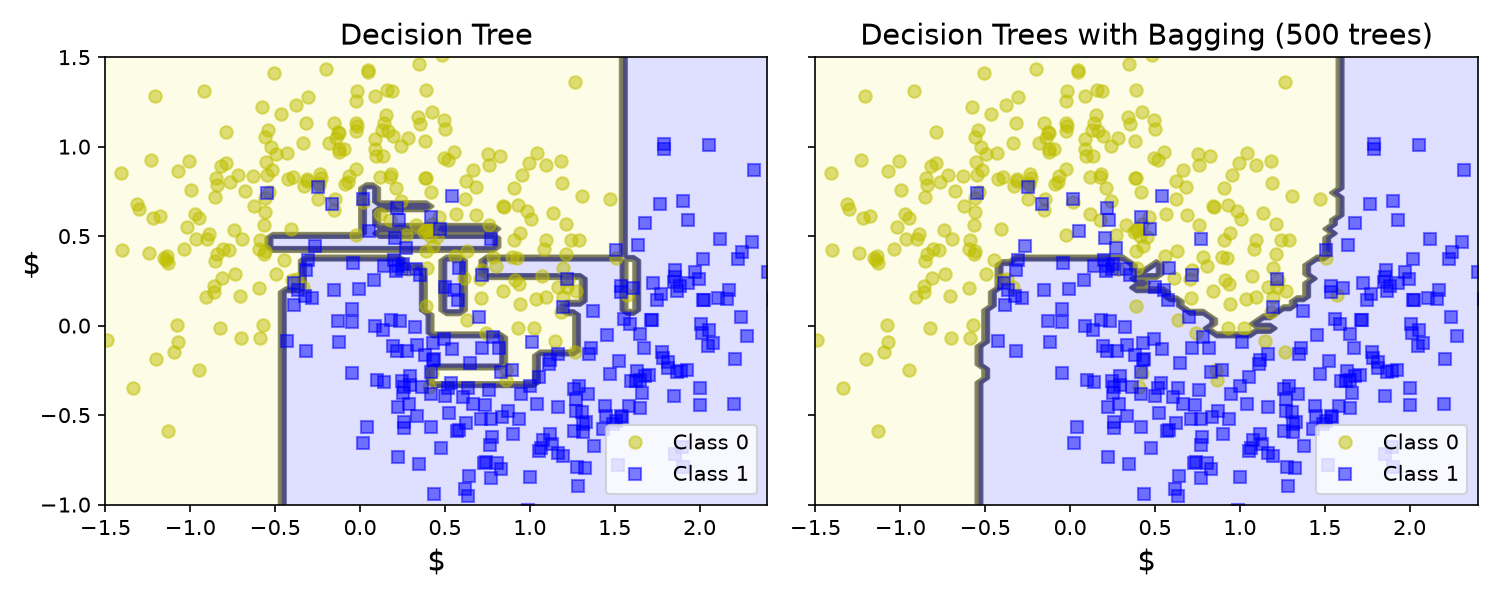

In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def plot_decision_boundary(clf, X, y, axes=[-1.5, 2.4, -1, 1.5], alpha=0.5, contour=True):
    x1s = np.linspace(axes[0], axes[1], 100)
    x2s = np.linspace(axes[2], axes[3], 100)
    x1, x2 = np.meshgrid(x1s, x2s)
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)
    custom_cmap = ListedColormap(['#fafab0', '#9898ff'])
    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)
    if contour:
        custom_cmap2 = ListedColormap(['#7d7d58', '#4c4c7f'])
        plt.contour(x1, x2, y_pred, cmap=custom_cmap2, alpha=0.8)
    plt.plot(X[:, 0][y == 0], X[:, 1][y == 0], 'yo', alpha=alpha, label='Class 0')
    plt.plot(X[:, 0][y == 1], X[:, 1][y == 1], 'bs', alpha=alpha, label='Class 1')
    plt.axis(axes)
    plt.xlabel(r'$x_1$', fontsize=14)
    plt.ylabel(r'$x_2$', fontsize=14, rotation=0)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_decision_boundary(tree_clf, X, y)
plt.title('Single Decision Tree', fontsize=14)
plt.legend(loc='lower right')

plt.sca(axes[1])
plot_decision_boundary(bag_clf, X, y)
plt.title('Decision Trees with Bagging (500 trees)', fontsize=14)
plt.ylabel('')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

> **Visual Takeaway (Figure 7-5):**
>- **Single Decision Tree (Left):** High variance with irregular, jagged boundaries trying to capture specific noisy data points.
>- **Bagging Ensemble (Right):** Much smoother and regularized decision boundary. The ensemble makes a comparable number of errors on the training set (similar bias), but generalizes significantly better to unseen data (much lower variance).

## 3. Out-of-Bag (OOB) Evaluation

With bagging (`bootstrap=True`), some instances may be sampled several times for any given predictor, while others may not be sampled at all.

- On average, only about **63.2%** of the training instances are sampled for each predictor ($1 - e^{-1} \approx 0.632$).
- The remaining **36.8%** that are never sampled by that predictor are called its **Out-of-Bag (OOB)** instances.
- **Built-in Validation Set:** Since a predictor never sees its OOB instances during training, it can be evaluated on them without needing a separate validation split or cross-validation.
- An ensemble's OOB score is computed by aggregating predictions for each instance using **only the predictors for which that instance was out-of-bag**.

In Scikit-Learn, set `oob_score=True` when instantiating `BaggingClassifier` to automatically request an out-of-bag evaluation after training.

In [5]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# BaggingClassifier with oob_score=True
bag_clf_oob = BaggingClassifier(
    DecisionTreeClassifier(random_state=42), n_estimators=500,
    oob_score=True, n_jobs=-1, random_state=42
)
bag_clf_oob.fit(X_train, y_train)

# Evaluate using the built-in out-of-bag score
print(f"OOB Evaluation Score: {bag_clf_oob.oob_score_:.3f} ({bag_clf_oob.oob_score_ * 100:.2f}%)")

# Compare with true test set performance
y_pred = bag_clf_oob.predict(X_test)
print(f"Test Set Accuracy:    {accuracy_score(y_test, y_pred):.3f} ({accuracy_score(y_test, y_pred) * 100:.2f}%)")

OOB Evaluation Score: 0.896 (89.60%)
Test Set Accuracy:    0.920 (92.00%)


### OOB Decision Function (Probabilities)

`bag_clf.oob_decision_function_` returns the estimated class probabilities for each training instance based *only* on the ensemble estimators that did not see that instance during training.

Let's inspect the first few instances and verify how Scikit-Learn arrives at the final `oob_score_`:

In [6]:
import numpy as np

# Estimated class probabilities for the first 5 training instances when out-of-bag
print("OOB Decision Function (First 5 training instances):\n", bag_clf_oob.oob_decision_function_[:5])

# Predict the class for each instance by taking the argmax of its OOB probabilities
oob_preds = np.argmax(bag_clf_oob.oob_decision_function_, axis=1)
manual_oob_accuracy = accuracy_score(y_train, oob_preds)

print(f"\nManual OOB Accuracy from decision function: {manual_oob_accuracy:.3f}")
print("Matches bag_clf_oob.oob_score_ exactly:", manual_oob_accuracy == bag_clf_oob.oob_score_)

OOB Decision Function (First 5 training instances):
 [[0.32352941 0.67647059]
 [0.3375     0.6625    ]
 [1.         0.        ]
 [0.         1.        ]
 [0.         1.        ]]

Manual OOB Accuracy from decision function: 0.896
Matches bag_clf_oob.oob_score_ exactly: True


> ### OOB Evaluation Takeaways
>
> | Evaluation Metric | Accuracy |
> | :--- | :--- |
> | **OOB Evaluation Score (Training Set)** | **89.6%** |
> | **Actual Test Set Accuracy** | **92.0%** |
>
> **Key Observations:**
> - **High Predictive Reliability:** The OOB evaluation estimated an accuracy of **89.6%**, which closely matches the actual test accuracy of **92.0%**. This confirms that OOB evaluation serves as an accurate, unbiased proxy for general test set performance.
> - **Computational Efficiency:** We obtained an out-of-sample performance estimate *without* setting aside a validation set (maximizing data available for training) and *without* having to train models $k$ times as required by cross-validation.
> - **Instance-Level Probabilities:** For instance 1, the predictors that didn't train on it gave it a 67.6% probability of belonging to class 1 (and 32.4% for class 0).

## 4. Random Forests

A **Random Forest** is an ensemble of Decision Trees, generally trained via the bagging method (with `bootstrap=True`), typically with `max_samples` set to the size of the training set.

Instead of manually creating a `BaggingClassifier` and passing it a `DecisionTreeClassifier`, Scikit-Learn provides the dedicated `RandomForestClassifier` class:
- **Convenient & Unified:** It encompasses both Decision Tree hyperparameters (controlling how trees grow) and Bagging hyperparameters (controlling ensemble aggregation).
- **Optimized Performance:** Optimized under the hood specifically for decision tree ensembles.
- **Extra Feature Randomness:** At each split node, instead of searching for the best feature among *all* features, it searches for the best feature among a **random subset of features** (`max_features="sqrt"` by default).

This extra randomness produces greater diversity among the individual trees, trading slightly higher bias for significantly lower variance.

In [7]:
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import numpy as np

# 1. Train a RandomForestClassifier
rnd_clf = RandomForestClassifier(n_estimators=500, max_leaf_nodes=16, n_jobs=-1, random_state=42)
rnd_clf.fit(X_train, y_train)
y_pred_rf = rnd_clf.predict(X_test)

# 2. Train a BaggingClassifier roughly equivalent to RandomForestClassifier
bag_clf = BaggingClassifier(
    DecisionTreeClassifier(splitter="random", max_leaf_nodes=16, random_state=42),
    n_estimators=500, max_samples=1.0, bootstrap=True, n_jobs=-1, random_state=42
)
bag_clf.fit(X_train, y_train)
y_pred_bag = bag_clf.predict(X_test)

# Evaluate and compare predictions
rf_acc = accuracy_score(y_test, y_pred_rf)
bag_acc = accuracy_score(y_test, y_pred_bag)
agreement = np.mean(y_pred_rf == y_pred_bag)

print(f"Random Forest Accuracy:              {rf_acc:.4f} ({rf_acc * 100:.2f}%)")
print(f"Equivalent Bagging Classifier Acc:   {bag_acc:.4f} ({bag_acc * 100:.2f}%)")
print(f"Prediction Agreement:                {agreement * 100:.2f}% ({np.sum(y_pred_rf == y_pred_bag)} / {len(y_pred_rf)} matching predictions)")

Random Forest Accuracy:              0.9120 (91.20%)
Equivalent Bagging Classifier Acc:   0.9200 (92.00%)
Prediction Agreement:                97.60% (122 / 125 matching predictions)


> ### Output Explanation & Random Forest Insights
>
> | Model | Test Accuracy | Prediction Agreement with RF |
> | :--- | :--- | :--- |
> | **RandomForestClassifier** | **91.20%** | **100%** (Baseline) |
> | **BaggingClassifier (`splitter="random"`)** | **92.00%** | **97.60%** (122 / 125 samples) |
>
> **What is going on here?**
> 1. **Direct Equivalence:** A `RandomForestClassifier` is essentially an ensemble of Decision Trees trained via Bagging (`bootstrap=True`, `max_samples=1.0`). Notice that **97.6% of the predictions match identically** between the two models. The minute difference stems from minor implementation differences in random feature selection.
> 2. **Why `splitter="random"` in Bagging?** A default Decision Tree searches for the best split threshold among *all* features. By setting `splitter="random"`, the decision tree chooses splits among random feature subsets, replicating the signature behavior of Random Forests.
> 3. **Dual Source of Randomness:** Random Forests inject randomness in two complementary ways:
>    - **Instance sampling (Row randomness):** Each tree trains on a bootstrap replicate (~63.2% unique instances).
>    - **Feature sampling (Column randomness):** At each node split, it only evaluates a random subset of features (`max_features="sqrt"`).
> 4. **Variance Reduction:** Individual trees have higher bias due to feature constraints, but when aggregated across 500 diverse trees, the ensemble variance is drastically reduced, producing superior overall generalization.